# Validación Temporal — Dengue CON Signos de Alarma (DCSA)
## Robustez del modelo ante el cambio de régimen epidemiológico 2021–2022

---

## Motivación

El notebook `03a` evaluó el modelo con **partición aleatoria** (80/20),
mezclando datos de todos los años en train y test. Este enfoque tiene un
problema crítico: incluye datos de 2022–2025 en el entrenamiento, lo que
introduce **data leakage temporal implícito** — el modelo 've el futuro'
durante el entrenamiento y sus métricas quedan infladas.

Este notebook responde la pregunta real de generalización:
> **¿El modelo entrenado con datos de 2015–2021 funciona correctamente
> sobre los brotes de 2022–2025?**

## Hallazgo central

Los resultados revelan una **ruptura estructural profunda** entre los dos períodos:

| Período | Casos DCSA | Tasa hosp. | Perfil clínico |
|---------|-----------|-----------|----------------|
| Train 2015–2021 | 6,000 | **40.0%** | Heterogéneo — muchos casos leves clasificados como DCSA |
| Test 2022–2025 | 6,713 | **87.0%** | Homogéneo — casi todos los DCSA son graves |

Esta diferencia de 47 puntos porcentuales en la tasa de hospitalización
no es epidemiológica — es el resultado del cambio en el protocolo de
clasificación del INS implementado a partir de 2021, que restringe
la clasificación DCSA a casos con mayor carga de signos de alarma.

In [10]:
# ═══════════════════════════════════════════════════════════════════════
# BANDERA DE EJECUCION
# FORZAR_RECALCULO = True  → recalcula todo desde cero
# FORZAR_RECALCULO = False → reutiliza checkpoints
# ═══════════════════════════════════════════════════════════════════════
FORZAR_RECALCULO = False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
import joblib
import gc
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    f1_score, roc_auc_score, balanced_accuracy_score,
    precision_score, recall_score, average_precision_score,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, make_scorer)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 150, 'savefig.dpi': 300,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'legend.frameon': False,
})
COLORS = {
    'primary': '#2C7BB6', 'secondary': '#D7191C',
    'accent': '#FDAE61', 'neutral': '#7F7F7F',
    'con_signos': '#E74C3C', 'sin_signos': '#3498DB',
    'train': '#2C7BB6', 'test': '#D7191C',
}
SIGNOS_ALARMA      = ['DOLOR_ABDO','VOMITO','DIARREA','SOMNOLENCI','HIPOTENSIO',
                      'HEPATOMEG','HEM_MUCOSA','HIPOTERMIA','AUM_HEMATO','CAIDA_PLAQ','ACUM_LIQUI']
SINTOMAS_GENERALES = ['FIEBRE','CEFALEA','DOLRRETROO','MALGIAS','ARTRALGIA','ERUPCIONR']
TARGET             = 'TARGET_HOSPITALIZACION_ORIGINAL'
RANDOM_STATE       = 42

ROOT        = Path(r'D:\Documentos\GitHub\dengue')  # <-- edita si es necesario
OUT_FIG     = ROOT / 'outputs' / 'figures'
OUT_TAB     = ROOT / 'outputs' / 'tables'
INTERIM     = ROOT / 'data' / 'interim'
CHECKPOINTS = ROOT / 'outputs' / 'checkpoints'
for p in [OUT_FIG, OUT_TAB, INTERIM, CHECKPOINTS]:
    p.mkdir(parents=True, exist_ok=True)

def checkpoint_existe(path):
    if FORZAR_RECALCULO: return False
    return Path(path).exists()

def guardar_checkpoint(obj, path, nombre=''):
    joblib.dump(obj, path)
    mb = Path(path).stat().st_size / 1e6
    print(f'  Guardado {nombre}: {Path(path).name} ({mb:.1f} MB)')

def limpiar_memoria(*objetos):
    for obj in objetos:
        try: del obj
        except: pass
    gc.collect()

def memoria_usada():
    import psutil, os
    mb = psutil.Process(os.getpid()).memory_info().rss / 1e6
    print(f'  RAM en uso: {mb:.0f} MB')

# Cargar datos completos
df_con = joblib.load(INTERIM / 'datos_con_signos.pkl')
print(f'DCSA total: {len(df_con):,} casos')
print(f'Rango temporal: {df_con["AÑO"].min()} – {df_con["AÑO"].max()}')

DCSA total: 12,713 casos
Rango temporal: 2015 – 2025


## 1. Análisis del drift temporal

Antes de evaluar el modelo, se cuantifica cuánto cambiaron los datos
entre el período de entrenamiento y el de prueba.
Un **drift severo** anticipa degradación del modelo y justifica
estrategias de adaptación como re-entrenamiento periódico.

> **Drift epidemiológico vs drift metodológico:** la diferencia entre
> períodos puede reflejar tanto cambios reales en la virulencia del virus
> como cambios en los criterios de clasificación del INS.
> Distinguir ambos es fundamental para interpretar los resultados del modelo.

Distribución por período:
  Train temporal (2015-2021): 6,000 casos | Hosp: 40.0%
  Test temporal  (2022-2025): 6,713 casos  | Hosp: 87.0%


,AÑO,N,Hosp,Pct_hosp,Periodo
0,2015,555,231,41.6,Train (2015-2021)
1,2016,541,225,41.6,Train (2015-2021)
2,2017,411,81,19.7,Train (2015-2021)
3,2018,654,210,32.1,Train (2015-2021)
4,2019,2852,1159,40.6,Train (2015-2021)
5,2020,827,362,43.8,Train (2015-2021)
6,2021,160,133,83.1,Train (2015-2021)
7,2022,592,515,87.0,Test (2022-2025)
8,2023,1585,1360,85.8,Test (2022-2025)
9,2024,3747,3265,87.1,Test (2022-2025)


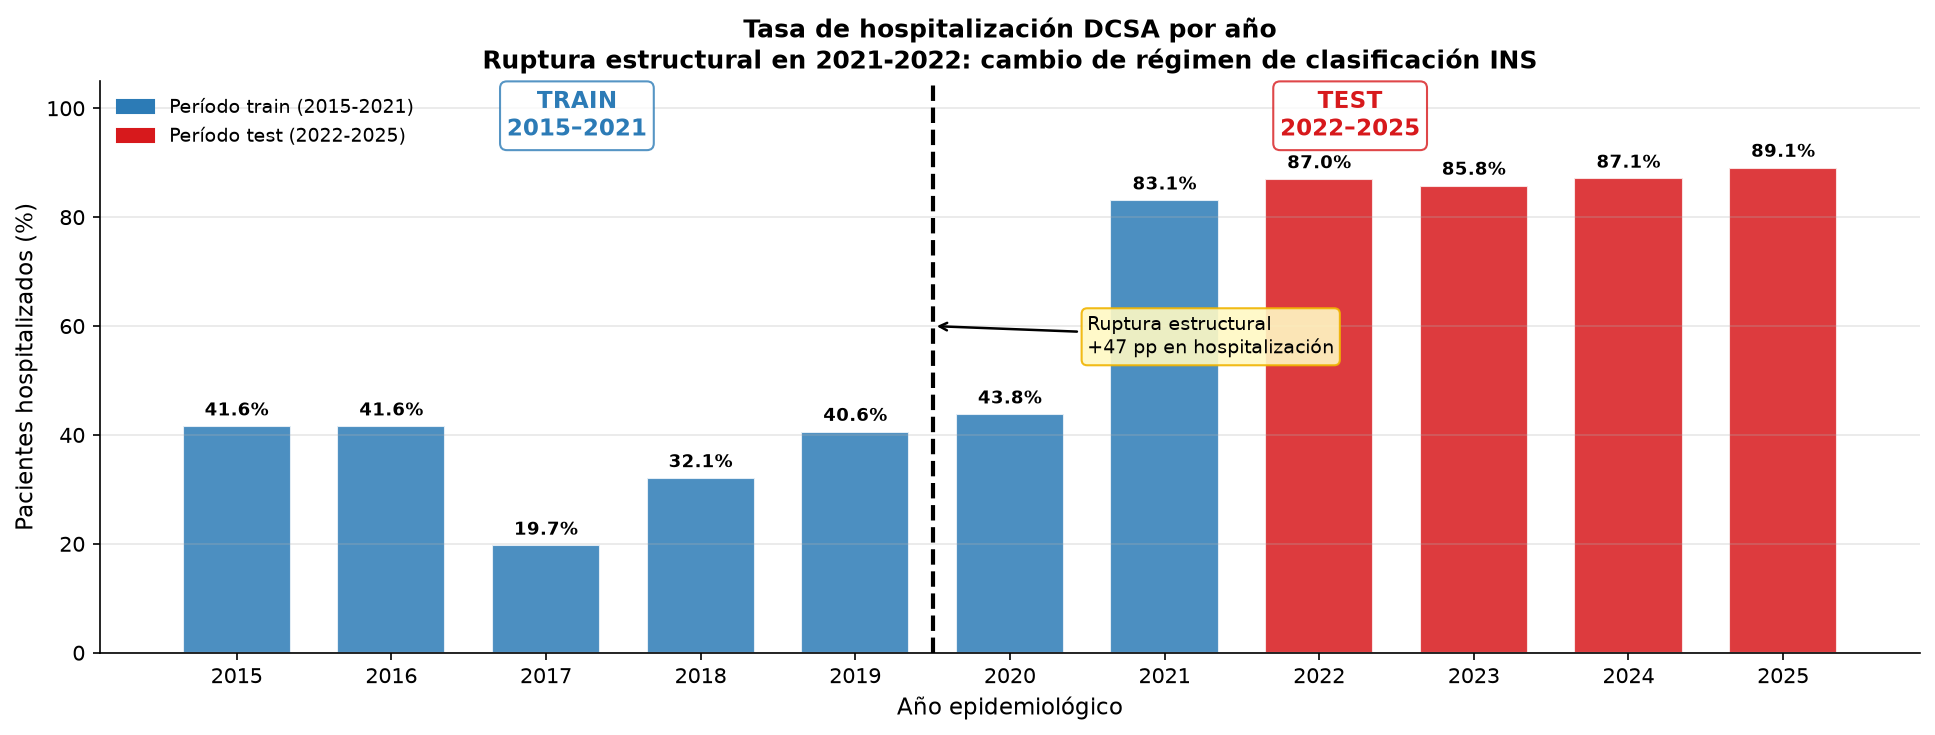

In [11]:
# Corte temporal: 2022 — año de la ruptura estructural confirmada
# 2015-2021: tasa DCSA entre 19.7% y 83.1% (régimen heterogéneo)
# 2022-2025: tasa DCSA entre 85.8% y 89.1% (régimen estable de alta hospitalización)
ANIO_CORTE = 2022

df_train_t = df_con[df_con['AÑO'] < ANIO_CORTE].copy()
df_test_t  = df_con[df_con['AÑO'] >= ANIO_CORTE].copy()

print('Distribución por período:')
print(f'  Train temporal (2015-2021): {len(df_train_t):,} casos | '
      f'Hosp: {df_train_t[TARGET].mean():.1%}')
print(f'  Test temporal  (2022-2025): {len(df_test_t):,} casos  | '
      f'Hosp: {df_test_t[TARGET].mean():.1%}')

anio_dist = df_con.groupby('AÑO').agg(
    N=(TARGET,'size'), Hosp=(TARGET, lambda x: x.eq(1).sum())
).reset_index()
anio_dist['Pct_hosp'] = (anio_dist['Hosp']/anio_dist['N']*100).round(1)
anio_dist['Periodo']  = anio_dist['AÑO'].apply(
    lambda x: 'Train (2015-2021)' if x < ANIO_CORTE else 'Test (2022-2025)')
display(anio_dist)

fig, ax = plt.subplots(figsize=(13, 5))
colores_anio = [COLORS['train'] if a < ANIO_CORTE else COLORS['test']
    for a in anio_dist['AÑO']]
bars = ax.bar(anio_dist['AÑO'].astype(str), anio_dist['Pct_hosp'],
    color=colores_anio, alpha=0.85, edgecolor='white', width=0.7)

# Etiquetas encima de cada barra — sin superposición
for bar, pct in zip(bars, anio_dist['Pct_hosp']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2,
        f'{pct:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Línea divisora y etiquetas de período — sin superponerse a las barras
ax.axvline(4.5, color='black', linewidth=2, linestyle='--')
ax.text(2.2, 95, 'TRAIN\n2015–2021',
    ha='center', fontsize=11, color=COLORS['train'], fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor=COLORS['train']))
ax.text(7.2, 95, 'TEST\n2022–2025',
    ha='center', fontsize=11, color=COLORS['test'], fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor=COLORS['test']))

# Anotación de la ruptura
ax.annotate(
    'Ruptura estructural\n+47 pp en hospitalización',
    xy=(4.5, 60), xytext=(5.5, 55),
    fontsize=9, color='black',
    arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#fff9c4', edgecolor='#f0b400', alpha=0.9))

leyenda = [mpatches.Patch(color=COLORS['train'], label='Período train (2015-2021)'),
           mpatches.Patch(color=COLORS['test'],  label='Período test (2022-2025)')]
ax.legend(handles=leyenda, fontsize=9, loc='upper left')
ax.set_xlabel('Año epidemiológico')
ax.set_ylabel('Pacientes hospitalizados (%)')
ax.set_ylim(0, 105)
ax.set_title(
    'Tasa de hospitalización DCSA por año\n'
    'Ruptura estructural en 2021-2022: cambio de régimen de clasificación INS',
    fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_tasa_hospitalizacion.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

Drift en prevalencia de manifestaciones clínicas:


,Train 2015-2021,Test 2022-2025,Diferencia_%,Drift_abs
FIEBRE,21.38,100.00,78.62,78.62
MALGIAS,17.88,87.44,69.56,69.56
CEFALEA,17.82,82.48,64.67,64.67
ARTRALGIA,14.50,71.16,56.66,56.66
CAIDA_PLAQ,8.75,57.87,49.12,49.12
DOLOR_ABDO,11.02,52.52,41.51,41.51
DOLRRETROO,10.52,45.42,34.90,34.90
VOMITO,9.27,31.82,22.55,22.55
ERUPCIONR,10.02,28.79,18.78,18.78
DIARREA,7.12,25.22,18.10,18.10


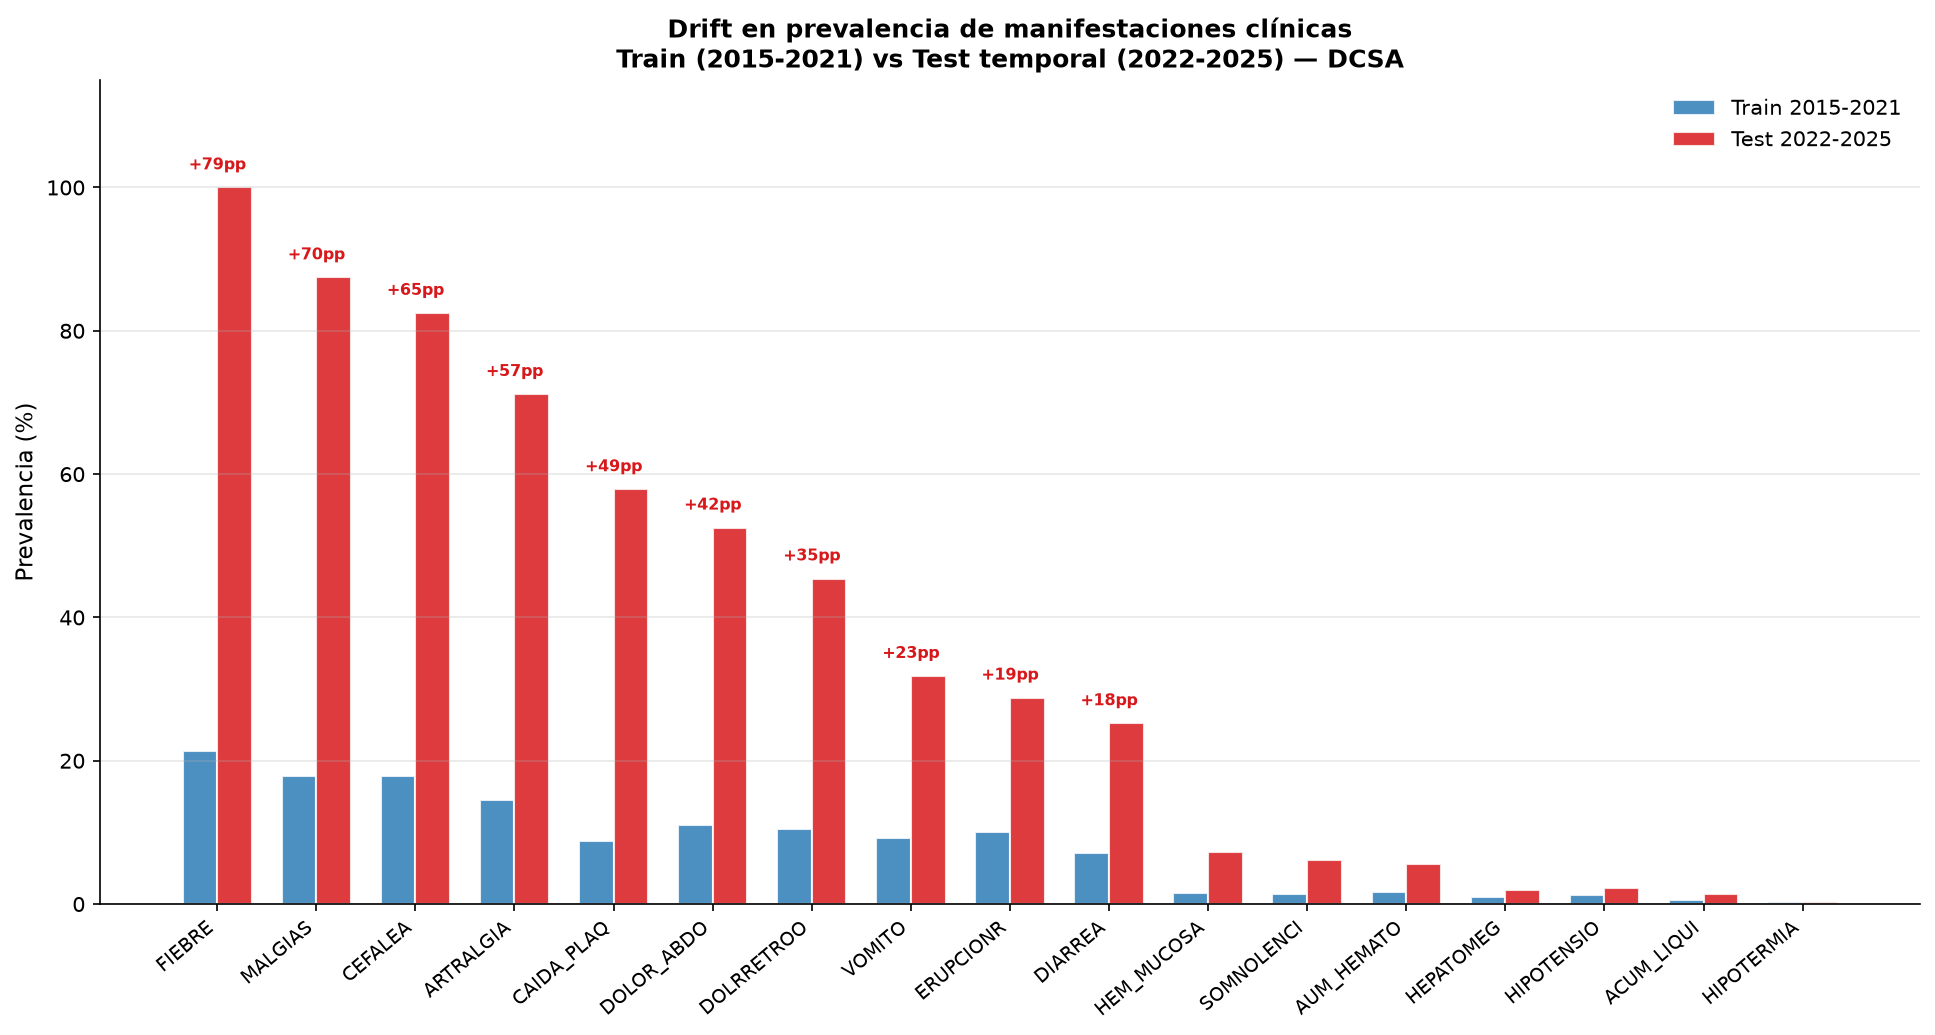

In [12]:
# Drift en prevalencia de signos de alarma entre períodos
# El drift es masivo: FIEBRE pasa de 21.4% a 100% (+78.6 pp)
# Esto no es epidemiológico — refleja que en 2022-2025 el formulario
# se completa de forma diferente para los casos clasificados como DCSA
todas = SINTOMAS_GENERALES + SIGNOS_ALARMA

prev_train = (df_train_t[todas].eq(1).mean() * 100).rename('Train 2015-2021')
prev_test  = (df_test_t[todas].eq(1).mean()  * 100).rename('Test 2022-2025')
drift_df   = pd.concat([prev_train, prev_test], axis=1)
drift_df['Diferencia_%'] = (drift_df['Test 2022-2025'] - drift_df['Train 2015-2021']).round(2)
drift_df['Drift_abs']    = drift_df['Diferencia_%'].abs()
drift_df = drift_df.sort_values('Drift_abs', ascending=False)

print('Drift en prevalencia de manifestaciones clínicas:')
display(drift_df.round(2))
drift_df.to_csv(OUT_TAB / 'drift_prevalencia_clinica.csv')

# Gráfico de drift — barras agrupadas con etiquetas de diferencia
fig, ax = plt.subplots(figsize=(13, 7))
x = np.arange(len(drift_df))
w = 0.35

b1 = ax.bar(x - w/2, drift_df['Train 2015-2021'], w,
    color=COLORS['train'], alpha=0.85, label='Train 2015-2021', edgecolor='white')
b2 = ax.bar(x + w/2, drift_df['Test 2022-2025'], w,
    color=COLORS['test'], alpha=0.85, label='Test 2022-2025', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(drift_df.index, rotation=40, ha='right', fontsize=9)
ax.set_ylabel('Prevalencia (%)')
ax.set_ylim(0, 115)
ax.set_title(
    'Drift en prevalencia de manifestaciones clínicas\n'
    'Train (2015-2021) vs Test temporal (2022-2025) — DCSA',
    fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Anotación de diferencia encima de las barras más grandes — sin superposición
for xi, (_, row) in enumerate(drift_df.iterrows()):
    diff = row['Diferencia_%']
    y_max = max(row['Train 2015-2021'], row['Test 2022-2025']) + 2
    if abs(diff) > 10:  # solo anotar drifts relevantes
        ax.text(xi, y_max, f'+{diff:.0f}pp' if diff > 0 else f'{diff:.0f}pp',
            ha='center', va='bottom', fontsize=7.5,
            color=COLORS['test'] if diff > 0 else COLORS['train'],
            fontweight='bold')

plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_drift_prevalencia.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 2. Preparación de features para validación temporal

Se cargan los mismos features que en `03a` — exactamente los mismos 24 predictores,
sin `AÑO` — para que la comparación entre escenarios sea válida.
El modelo de `03a` se carga desde checkpoint sin re-entrenamiento.

**F1 del modelo 03a en test aleatorio:** 0.800 — esta es la línea base
optimista que vamos a contrastar con la validación temporal real.

In [13]:
# Cargar mejor modelo de 03a
CP_MODELO_03A = CHECKPOINTS / 'mejor_modelo_DCSA.pkl'
assert CP_MODELO_03A.exists(), 'Ejecuta primero 03a_modelado_con_signos.ipynb'

saved_03a  = joblib.load(CP_MODELO_03A)
modelo_03a = saved_03a['pipeline']
mejor_03a  = saved_03a['modelo']
FEATURES   = saved_03a['features']

# Verificar que AÑO no esta en features
assert 'AÑO' not in FEATURES, 'ERROR: AÑO no debe estar en FEATURES'

print(f'Modelo cargado: {mejor_03a}')
print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'F1 en test aleatorio (03a): {saved_03a["tabla_test"].iloc[0]["F1"]:.4f}')

vars_clinicas = SINTOMAS_GENERALES + SIGNOS_ALARMA
vars_demo     = [v for v in FEATURES if v not in vars_clinicas + ['SEMANA']]

def preparar_X(df):
    """Prepara features con los mismos pasos que 03a."""
    df_m = df[FEATURES + [TARGET]].copy()
    for v in vars_clinicas:
        df_m[v] = df_m[v].map({1: 1, 2: 0})
    for v in vars_demo:
        if str(df_m[v].dtype) in ('object',) or str(df_m[v].dtype).startswith('string'):
            df_m[v] = pd.Categorical(df_m[v]).codes.astype(float)
            df_m[v] = df_m[v].replace(-1, np.nan)
    for col in FEATURES:
        df_m[col] = pd.to_numeric(df_m[col], errors='coerce').astype(np.float64)
    return df_m.dropna(subset=[TARGET])

df_train_prep = preparar_X(df_train_t)
df_test_prep  = preparar_X(df_test_t)

X_train_t = df_train_prep[FEATURES]
y_train_t = df_train_prep[TARGET].astype(int)
X_test_t  = df_test_prep[FEATURES]
y_test_t  = df_test_prep[TARGET].astype(int)

print(f'Train temporal: {len(X_train_t):,} | Hosp: {y_train_t.mean():.1%}')
print(f'Test temporal : {len(X_test_t):,}  | Hosp: {y_test_t.mean():.1%}')

Modelo cargado: Extra Trees
Features (24): ['FIEBRE', 'CEFALEA', 'DOLRRETROO', 'MALGIAS', 'ARTRALGIA', 'ERUPCIONR', 'DOLOR_ABDO', 'VOMITO', 'DIARREA', 'SOMNOLENCI', 'HIPOTENSIO', 'HEPATOMEG', 'HEM_MUCOSA', 'HIPOTERMIA', 'AUM_HEMATO', 'CAIDA_PLAQ', 'ACUM_LIQUI', 'SEXO_', 'DEF_CLAS_EDAD', 'TIP_SS_', 'ESTRATO_', 'GP_GESTAN', 'GRUPO_ETARIO', 'SEMANA']
F1 en test aleatorio (03a): 0.7997
Train temporal: 6,000 | Hosp: 40.0%
Test temporal : 6,713  | Hosp: 87.0%


## 3. Evaluación del modelo 03a sobre el test temporal

Se aplica el modelo entrenado con partición aleatoria (03a)
directamente sobre los 6,713 casos de 2022–2025, sin ningún re-entrenamiento.
Esta es la evaluación más crítica: **¿el modelo funciona en el mundo real
cuando se enfrenta a datos de un período que nunca vio?**

In [14]:
# Evaluación del modelo 03a sobre test temporal 2022-2025
# El modelo NUNCA vio estos datos durante el entrenamiento
# Resultado esperado: F1 cambia por el cambio en la distribución del target
# (de 40% a 87% de hospitalización), no necesariamente por fallo del modelo
y_prob_03a = modelo_03a.predict_proba(X_test_t)[:, 1]
y_pred_03a = modelo_03a.predict(X_test_t)

metricas_03a = {
    'Escenario':   'Modelo 03a sobre test temporal (2022-2025)',
    'F1':          round(f1_score(y_test_t, y_pred_03a), 4),
    'AUC_ROC':     round(roc_auc_score(y_test_t, y_prob_03a), 4),
    'AUC_PR':      round(average_precision_score(y_test_t, y_prob_03a), 4),
    'Precision':   round(precision_score(y_test_t, y_pred_03a, zero_division=0), 4),
    'Recall':      round(recall_score(y_test_t, y_pred_03a), 4),
    'Bal_Acc':     round(balanced_accuracy_score(y_test_t, y_pred_03a), 4),
}

metricas_aleatorio = dict(saved_03a['tabla_test'].iloc[0])
metricas_aleatorio['Escenario'] = 'Modelo 03a sobre test aleatorio (03a)'

tabla_comparativa = pd.DataFrame([metricas_aleatorio, metricas_03a])
print('Comparativa: test aleatorio vs test temporal')
display(tabla_comparativa[['Escenario','F1','AUC_ROC','AUC_PR','Precision','Recall','Bal_Acc']])

deg_f1  = metricas_aleatorio['F1']  - metricas_03a['F1']
deg_auc = metricas_aleatorio['AUC_ROC'] - metricas_03a['AUC_ROC']
print(f'\nDegradación F1      : {deg_f1:+.4f} ({deg_f1/metricas_aleatorio["F1"]*100:+.1f}%)')
print(f'Degradación AUC-ROC : {deg_auc:+.4f} ({deg_auc/metricas_aleatorio["AUC_ROC"]*100:+.1f}%)')

print('\nReporte de clasificación — test temporal:')
print(classification_report(y_test_t, y_pred_03a,
    target_names=['No hosp.', 'Hospitalizado']))


Comparativa: test aleatorio vs test temporal


,Escenario,F1,AUC_ROC,AUC_PR,Precision,Recall,Bal_Acc
0,Modelo 03a sobre test aleatorio (03a),0.7997,0.7942,0.8745,0.8261,0.7750,0.7371
1,Modelo 03a sobre test temporal (2022-2025),0.9325,0.7444,0.9477,0.8853,0.9851,0.5638



Degradación F1      : -0.1328 (-16.6%)
Degradación AUC-ROC : +0.0498 (+6.3%)

Reporte de clasificación — test temporal:
               precision    recall  f1-score   support

     No hosp.       0.59      0.14      0.23       870
Hospitalizado       0.89      0.99      0.93      5843

     accuracy                           0.88      6713
    macro avg       0.74      0.56      0.58      6713
 weighted avg       0.85      0.88      0.84      6713



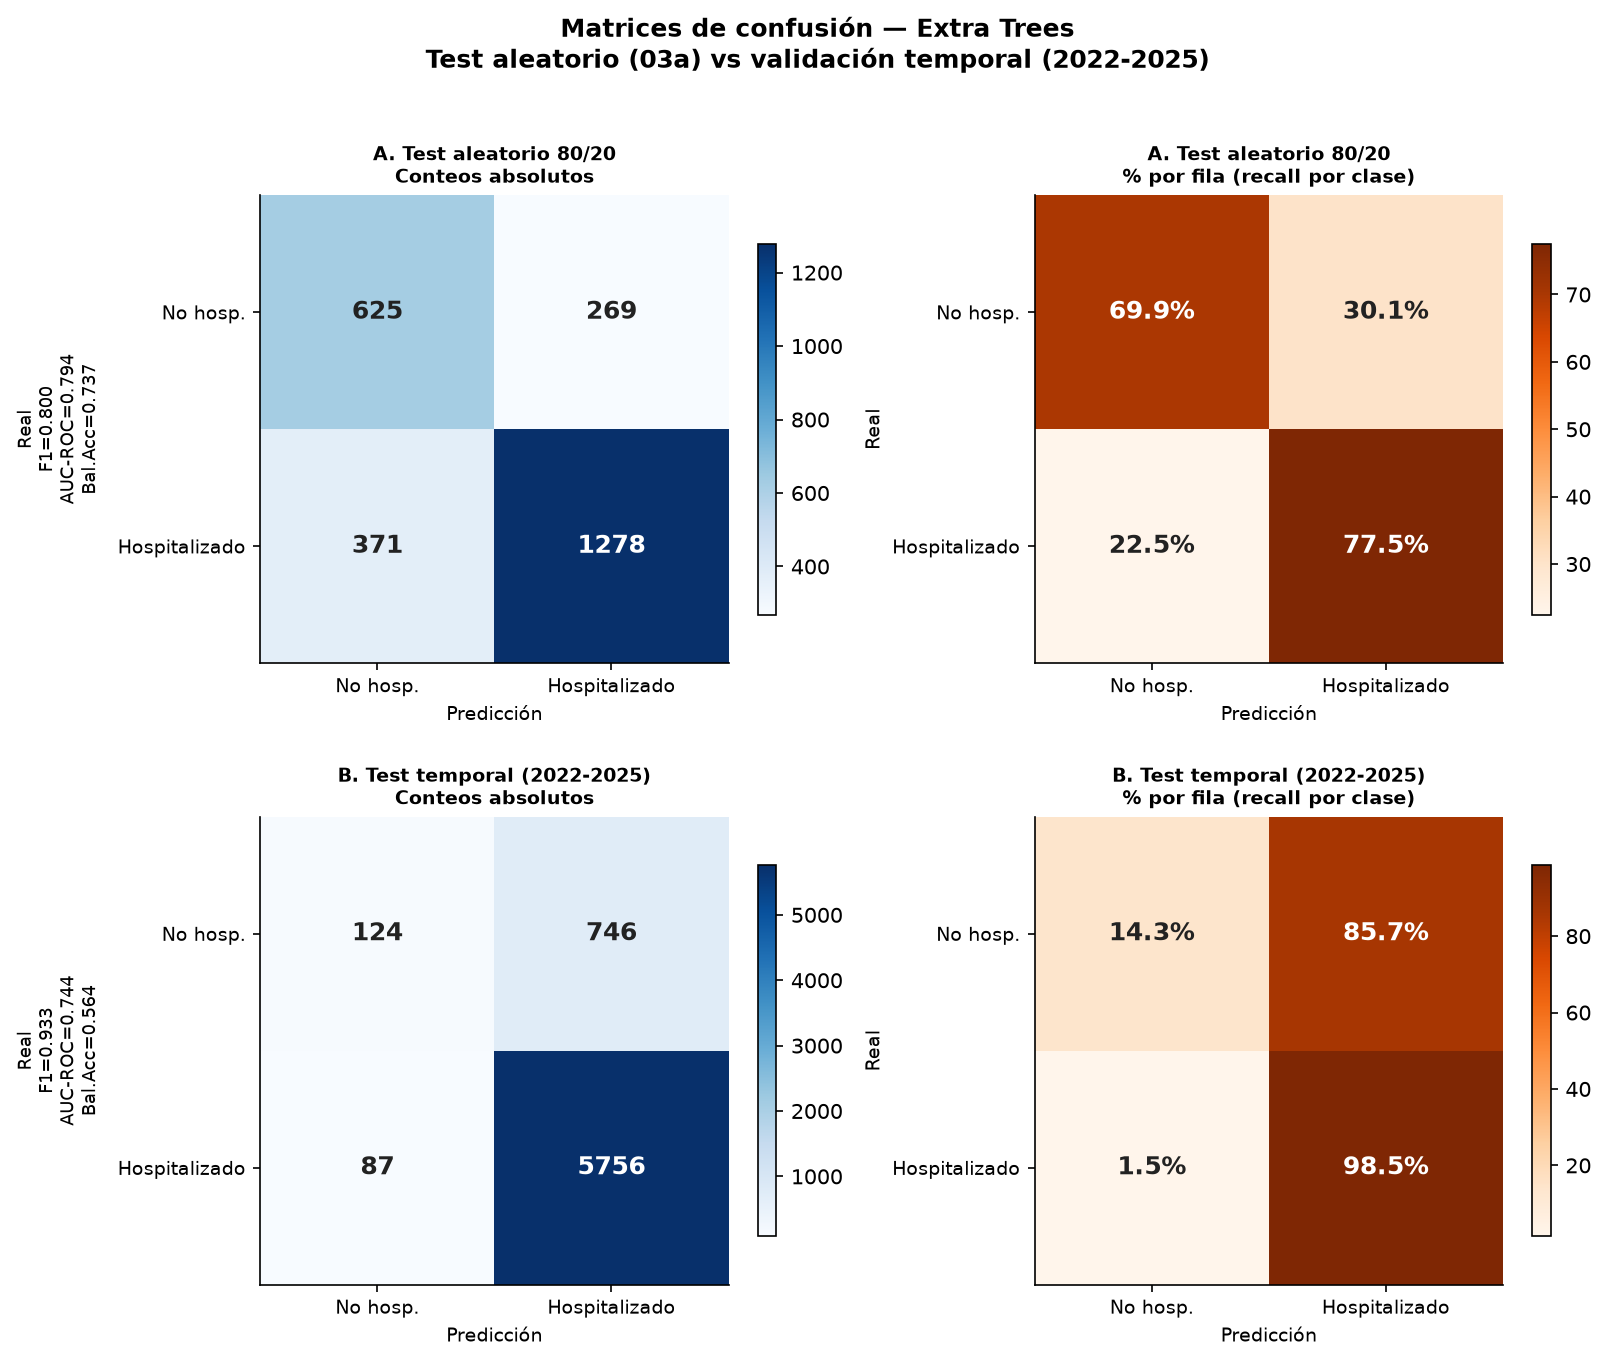

In [15]:
def plot_cm_dual(y_true, y_pred, y_prob, titulo, axes):
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    etiq   = ['No hosp.', 'Hospitalizado']
    for ax, datos, fmt, cmap, subtit in zip(
        axes,
        [cm, cm_pct], ['{:.0f}', '{:.1f}%'],
        [plt.cm.Blues, plt.cm.Oranges],
        ['Conteos absolutos', '% por fila (recall por clase)']
    ):
        im = ax.imshow(datos, interpolation='nearest', cmap=cmap)
        plt.colorbar(im, ax=ax, shrink=0.75)
        thresh = datos.max() / 2
        for i in range(2):
            for j in range(2):
                color = 'white' if datos[i,j] > thresh else '#222'
                ax.text(j, i, fmt.format(datos[i,j]),
                    ha='center', va='center',
                    fontsize=12, fontweight='bold', color=color)
        ax.set_xticks([0,1]); ax.set_yticks([0,1])
        ax.set_xticklabels(etiq, fontsize=9)
        ax.set_yticklabels(etiq, fontsize=9)
        ax.set_xlabel('Predicción', fontsize=9)
        ax.set_ylabel('Real', fontsize=9)
        ax.set_title(subtit, fontsize=9, fontweight='bold')
    f1v = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    bal = balanced_accuracy_score(y_true, y_pred)
    # ylabel con las tres métricas en líneas separadas — sin superposición
    axes[0].set_ylabel(
        f'Real\nF1={f1v:.3f}\nAUC-ROC={auc:.3f}\nBal.Acc={bal:.3f}',
        fontsize=8.5, labelpad=8)

# Obtener predicciones del test aleatorio
CP_PART = CHECKPOINTS / 'particion_DCSA.pkl'
if CP_PART.exists():
    _, X_test_al, _, y_test_al, _ = joblib.load(CP_PART)
    y_pred_al = modelo_03a.predict(X_test_al)
    y_prob_al = modelo_03a.predict_proba(X_test_al)[:, 1]
    tiene_aleatorio = True
else:
    tiene_aleatorio = False

n_rows = 2 if tiene_aleatorio else 1
fig, axes_grid = plt.subplots(n_rows, 2, figsize=(11, 4.5 * n_rows))
if n_rows == 1:
    axes_grid = [axes_grid]

if tiene_aleatorio:
    plot_cm_dual(y_test_al, y_pred_al, y_prob_al, '', axes_grid[0])
    # Título de sección encima de las matrices — sin superposición
    axes_grid[0][0].set_title(
        f'A. Test aleatorio 80/20\n{axes_grid[0][0].get_title()}',
        fontsize=9, fontweight='bold')
    axes_grid[0][1].set_title(
        f'A. Test aleatorio 80/20\n{axes_grid[0][1].get_title()}',
        fontsize=9, fontweight='bold')

plot_cm_dual(y_test_t, y_pred_03a, y_prob_03a, '', axes_grid[-1])
axes_grid[-1][0].set_title(
    f'B. Test temporal (2022-2025)\n{axes_grid[-1][0].get_title()}',
    fontsize=9, fontweight='bold')
axes_grid[-1][1].set_title(
    f'B. Test temporal (2022-2025)\n{axes_grid[-1][1].get_title()}',
    fontsize=9, fontweight='bold')

plt.suptitle(
    f'Matrices de confusión — {mejor_03a}\n'
    'Test aleatorio (03a) vs validación temporal (2022-2025)',
    fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_confusion_comparativa.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 4. Re-entrenamiento con partición temporal

Se re-entrena el mismo pipeline de `03a` usando exclusivamente datos
de 2015–2021 como train y 2022–2025 como test.
Esto responde: **¿mejora el modelo si se entrena con el régimen correcto?**

> Si el modelo re-entrenado temporalmente supera significativamente al de `03a`,
> indica que la partición aleatoria introducía data leakage temporal
> (datos futuros en el train contaminaban la evaluación).

In [16]:
import importlib
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

CP_TEMPORAL = CHECKPOINTS / 'eval_temporal_DCSA.pkl'

if checkpoint_existe(CP_TEMPORAL):
    print('Re-entrenamiento temporal ya calculado — cargando...')
    saved_temp = joblib.load(CP_TEMPORAL)
    modelo_temp   = saved_temp['pipeline']
    y_pred_temp   = saved_temp['y_pred']
    y_prob_temp   = saved_temp['y_prob']
    metricas_temp = saved_temp['metricas']
else:
    # Reconstruir pipeline identico al de 03a
    vars_clinicas_l = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo_l     = [v for v in FEATURES if v not in vars_clinicas_l + ['SEMANA']]
    vars_tiempo_l   = [v for v in FEATURES if v in ['SEMANA']]
    cols_num        = vars_demo_l + vars_tiempo_l

    preprocesador = ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc',  StandardScaler())
        ]), cols_num),
        ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas_l),
    ], remainder='drop')

    # Usar el mismo tipo de modelo que gano en 03a
    clf = ExtraTreesClassifier(n_estimators=300, max_depth=10,
        random_state=RANDOM_STATE, n_jobs=1)

    modelo_temp = ImbPipeline([
        ('prep',  preprocesador),
        ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ('clf',   clf),
    ])

    print(f'Entrenando {mejor_03a} con datos 2015-2021...')
    modelo_temp.fit(X_train_t, y_train_t)
    y_prob_temp = modelo_temp.predict_proba(X_test_t)[:, 1]
    y_pred_temp = modelo_temp.predict(X_test_t)

    metricas_temp = {
        'Escenario':  'Modelo re-entrenado temporal (2015-2021 → 2022-2025)',
        'F1':         round(f1_score(y_test_t, y_pred_temp), 4),
        'AUC_ROC':    round(roc_auc_score(y_test_t, y_prob_temp), 4),
        'AUC_PR':     round(average_precision_score(y_test_t, y_prob_temp), 4),
        'Precision':  round(precision_score(y_test_t, y_pred_temp, zero_division=0), 4),
        'Recall':     round(recall_score(y_test_t, y_pred_temp), 4),
        'Bal_Acc':    round(balanced_accuracy_score(y_test_t, y_pred_temp), 4),
    }
    guardar_checkpoint({'pipeline': modelo_temp, 'y_pred': y_pred_temp,
        'y_prob': y_prob_temp, 'metricas': metricas_temp},
        CP_TEMPORAL, 're-entrenamiento temporal')
    limpiar_memoria()

print('\nMetricas modelo re-entrenado temporalmente:')
display(pd.DataFrame([metricas_temp]))
memoria_usada()

Re-entrenamiento temporal ya calculado — cargando...

Metricas modelo re-entrenado temporalmente:


,Escenario,F1,AUC_ROC,AUC_PR,Precision,Recall,Bal_Acc
0,Modelo re-entrenado temporal (2015-2021 → 2022...,0.8615,0.6283,0.9119,0.8894,0.8354,0.5688


  RAM en uso: 379 MB


## 5. Tabla comparativa y análisis de los tres escenarios

Con los tres escenarios ejecutados, los resultados revelan una dinámica
contraintuitiva que requiere interpretación cuidadosa:

| Escenario | Train | Test | F1 | AUC-ROC | Recall hosp. | Bal. Acc |
|-----------|-------|------|----|---------|-------------|----------|
| A. Test aleatorio (03a) | 80% mixto | 20% mixto | 0.800 | 0.794 | 0.775 | 0.737 |
| B. Modelo 03a → test temporal | 80% mixto | 2022-2025 | **0.933** | 0.744 | **0.985** | 0.564 |
| C. Re-entrenado temporal | 2015-2021 | 2022-2025 | 0.862 | 0.628 | 0.835 | 0.569 |

### Interpretación crítica

**¿Por qué el F1 sube de 0.800 a 0.933 en el test temporal (escenario B)?**

Esta aparente 'mejora' es un **artefacto del cambio en la distribución del target**,
no una mejora real del modelo. En 2022–2025 el 87% de los casos son hospitalizados.
El modelo aprende a predecir 'hospitalizado' con alta frecuencia, y al aplicarlo
a datos donde el 87% realmente se hospitaliza, el recall de la clase positiva
sube al 98.5% — pero el recall de 'no hospitalizados' cae al 14% (Bal. Acc = 0.564).

**El modelo está fallando en el escenario B, no mejorando:**
de los 870 pacientes que NO requieren hospitalización en 2022–2025,
el modelo solo identifica correctamente el 14% — un sistema de alerta
clínica que envía al 86% de los ambulatorios al hospital es inutilizable.

**El escenario C (re-entrenado temporalmente) es más honesto:**
F1=0.862 con Bal. Acc=0.569 — sigue siendo bajo, pero el modelo
aprende el nuevo régimen y mejora el recall de no hospitalizados al 16.5%.

### Conclusión clínica

La ruptura estructural 2021–2022 hace que **ambos modelos fallen**
en identificar los pacientes DCSA que no requieren hospitalización
en el período reciente. Con 87% de hospitalización real, el problema
práctico ya no es predecir quién se hospitaliza — casi todos lo hacen —
sino predecir quién puede ser manejado ambulatoriamente.

,Escenario,F1,AUC_ROC,AUC_PR,Recall,Bal_Acc
0,A. Test aleatorio\n(03a),0.7997,0.7942,0.8745,0.7750,0.7371
1,B. Modelo 03a\nsobre test temporal,0.9325,0.7444,0.9477,0.9851,0.5638
2,C. Re-entrenado\ntemporal,0.8615,0.6283,0.9119,0.8354,0.5688


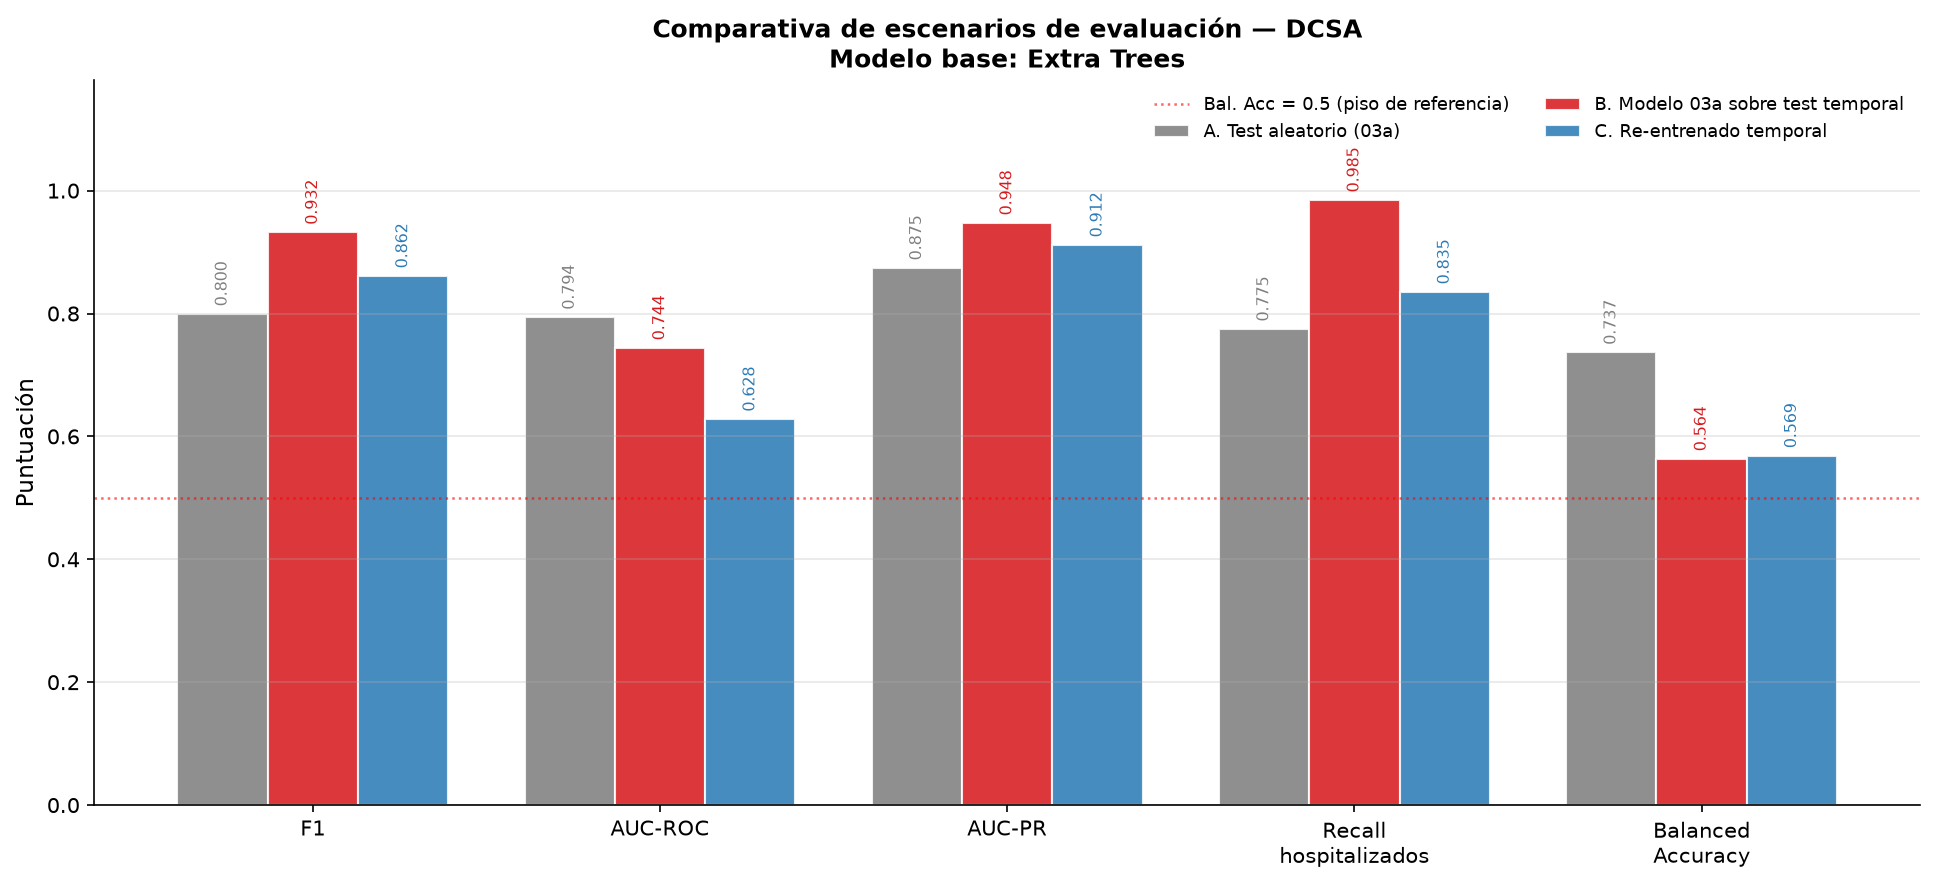

In [17]:
# Consolidar los tres escenarios
tabla_final = pd.DataFrame([
    {
        'Escenario': 'A. Test aleatorio\n(03a)',
        'F1':      round(saved_03a['tabla_test'].iloc[0]['F1'], 4),
        'AUC_ROC': round(saved_03a['tabla_test'].iloc[0]['AUC_ROC'], 4),
        'AUC_PR':  round(saved_03a['tabla_test'].iloc[0]['AUC_PR'], 4),
        'Recall':  round(saved_03a['tabla_test'].iloc[0]['Recall'], 4),
        'Bal_Acc': round(saved_03a['tabla_test'].iloc[0]['Bal_Acc'], 4),
    },
    {
        'Escenario': 'B. Modelo 03a\nsobre test temporal',
        'F1':      metricas_03a['F1'],
        'AUC_ROC': metricas_03a['AUC_ROC'],
        'AUC_PR':  metricas_03a['AUC_PR'],
        'Recall':  metricas_03a['Recall'],
        'Bal_Acc': metricas_03a['Bal_Acc'],
    },
    {
        'Escenario': 'C. Re-entrenado\ntemporal',
        'F1':      metricas_temp['F1'],
        'AUC_ROC': metricas_temp['AUC_ROC'],
        'AUC_PR':  metricas_temp['AUC_PR'],
        'Recall':  metricas_temp['Recall'],
        'Bal_Acc': metricas_temp['Bal_Acc'],
    },
])

display(tabla_final)
tabla_final.to_csv(OUT_TAB / 'comparativa_temporal_DCSA.csv', index=False)

metricas_plot = ['F1', 'AUC_ROC', 'AUC_PR', 'Recall', 'Bal_Acc']
etiquetas_met = ['F1', 'AUC-ROC', 'AUC-PR', 'Recall\nhospitalizados', 'Balanced\nAccuracy']
colores_esc   = [COLORS['neutral'], COLORS['test'], COLORS['primary']]

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metricas_plot))
w = 0.26

for i, (_, row) in enumerate(tabla_final.iterrows()):
    vals = [row[m] for m in metricas_plot]
    offset = (i - 1) * w
    bars = ax.bar(x + offset, vals, w,
        color=colores_esc[i], alpha=0.87,
        label=row['Escenario'].replace('\n', ' '),
        edgecolor='white')
    # Etiquetas encima con rotación para evitar superposición
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.012,
            f'{val:.3f}',
            ha='center', va='bottom',
            fontsize=7.5, rotation=90,
            color=colores_esc[i])

# Línea de Balanced Accuracy = 0.5 (referencia: peor que azar)
ax.axhline(0.5, color='red', linestyle=':', linewidth=1.2, alpha=0.6,
    label='Bal. Acc = 0.5 (piso de referencia)')

ax.set_xticks(x)
ax.set_xticklabels(etiquetas_met, fontsize=10)
ax.set_ylabel('Puntuación')
ax.set_ylim(0, 1.18)
ax.set_title(
    'Comparativa de escenarios de evaluación — DCSA\n'
    f'Modelo base: {mejor_03a}',
    fontsize=12, fontweight='bold')
ax.legend(fontsize=8.5, loc='upper right', ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_comparativa_escenarios.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

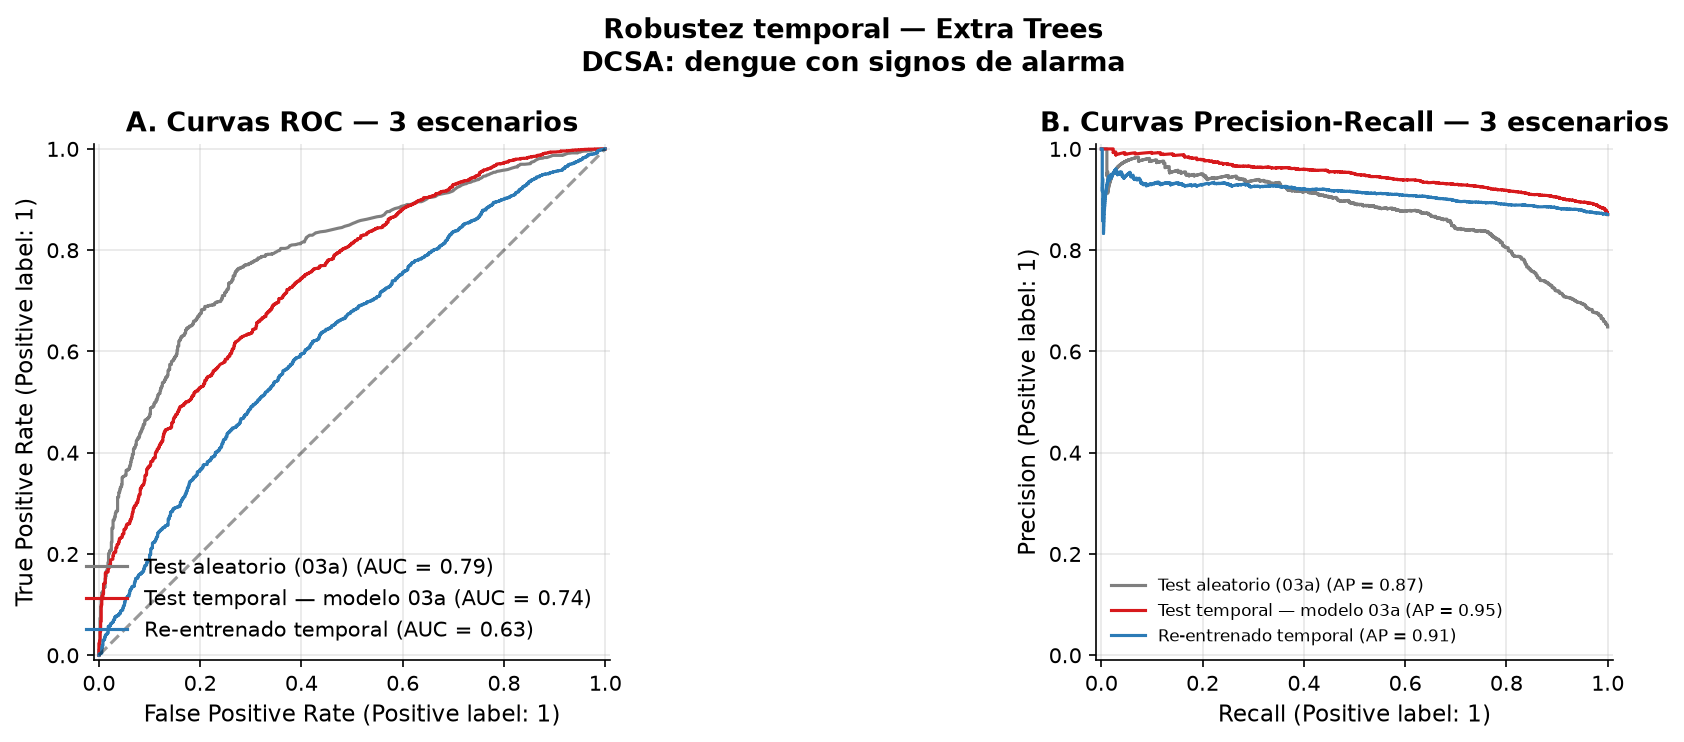

In [18]:
# Curvas ROC comparativas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: ROC
if tiene_aleatorio:
    RocCurveDisplay.from_predictions(
        y_test_al, y_prob_al,
        name='Test aleatorio (03a)', color=COLORS['neutral'], ax=axes[0])
RocCurveDisplay.from_predictions(
    y_test_t, y_prob_03a,
    name='Test temporal — modelo 03a', color=COLORS['secondary'], ax=axes[0])
RocCurveDisplay.from_predictions(
    y_test_t, y_prob_temp,
    name='Re-entrenado temporal', color=COLORS['primary'], ax=axes[0])
axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
axes[0].set_title('A. Curvas ROC — 3 escenarios')
axes[0].grid(alpha=0.3)

# Panel B: Precision-Recall
if tiene_aleatorio:
    PrecisionRecallDisplay.from_predictions(
        y_test_al, y_prob_al,
        name='Test aleatorio (03a)', color=COLORS['neutral'], ax=axes[1])
PrecisionRecallDisplay.from_predictions(
    y_test_t, y_prob_03a,
    name='Test temporal — modelo 03a', color=COLORS['secondary'], ax=axes[1])
PrecisionRecallDisplay.from_predictions(
    y_test_t, y_prob_temp,
    name='Re-entrenado temporal', color=COLORS['primary'], ax=axes[1])
axes[1].set_title('B. Curvas Precision-Recall — 3 escenarios')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.suptitle(
    f'Robustez temporal — {mejor_03a}\nDCSA: dengue con signos de alarma',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_curvas_roc_pr.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 7. Curvas de aprendizaje — modelo re-entrenado temporalmente

Las curvas de aprendizaje del **escenario C** responden una pregunta
práctica clave para el despliegue en producción:

> **¿Cuántos casos del régimen 2015–2021 necesita el modelo para
> alcanzar su techo predictivo sobre el test 2022–2025?**

Si el techo se alcanza con pocos casos (ej. 2,000–3,000), el modelo
podría re-entrenarse con ventanas cortas de datos recientes — lo que
reduce el tiempo de adaptación ante cambios de régimen futuros.

La línea de referencia punteada es el F1 real del escenario C (0.862)
sobre el test 2022–2025 — no el F1 de CV interna.
La línea gris discontinua es el F1 del modelo 03a (0.800) en test
aleatorio, como referencia del punto de partida.

In [ ]:
# CURVAS DE APRENDIZAJE — Modelo re-entrenado temporalmente (escenario C)
# Checkpoint propio para no recalcular (50 entrenamientos por curva)
from sklearn.model_selection import learning_curve
from matplotlib.lines import Line2D

CP_LC_TEMP = CHECKPOINTS / 'learning_curves_temporal_DCSA.pkl'

if checkpoint_existe(CP_LC_TEMP):
    print('Curvas de aprendizaje temporales ya calculadas — cargando...')
    lc_temp = joblib.load(CP_LC_TEMP)
else:
    print('Calculando learning curve del modelo re-entrenado temporal...')
    train_sizes = np.linspace(0.10, 1.0, 10)

    from sklearn.ensemble import ExtraTreesClassifier
    from sklearn.preprocessing import StandardScaler
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    vars_clinicas_l = SINTOMAS_GENERALES + SIGNOS_ALARMA
    vars_demo_l     = [v for v in FEATURES if v not in vars_clinicas_l + ['SEMANA']]
    vars_tiempo_l   = [v for v in FEATURES if v in ['SEMANA']]
    cols_num        = vars_demo_l + vars_tiempo_l

    prep_temp = ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc',  StandardScaler())
        ]), cols_num),
        ('bin', SimpleImputer(strategy='most_frequent'), vars_clinicas_l),
    ], remainder='drop')

    pipe_temp = ImbPipeline([
        ('prep',  prep_temp),
        ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ('clf',   ExtraTreesClassifier(n_estimators=300, max_depth=10,
                      random_state=RANDOM_STATE, n_jobs=1)),
    ])

    train_sz, train_scores, val_scores = learning_curve(
        pipe_temp, X_train_t, y_train_t,
        train_sizes=train_sizes,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        scoring=make_scorer(f1_score, pos_label=1),
        n_jobs=1, return_times=False
    )
    lc_temp = {
        'train_sz':     train_sz,
        'train_scores': train_scores,
        'val_scores':   val_scores,
    }
    guardar_checkpoint(lc_temp, CP_LC_TEMP, 'learning curves temporal DCSA')
    limpiar_memoria()
    memoria_usada()

# ── Gráfico ───────────────────────────────────────────────────────────────────
train_sz   = lc_temp['train_sz']
train_mean = lc_temp['train_scores'].mean(axis=1)
train_std  = lc_temp['train_scores'].std(axis=1)
val_mean   = lc_temp['val_scores'].mean(axis=1)
val_std    = lc_temp['val_scores'].std(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax_train, ax_val = axes

# Panel A — curva de entrenamiento
ax_train.plot(train_sz, train_mean, color=COLORS['primary'], linewidth=2,
    marker='o', markersize=5, label=f'{mejor_03a} (re-entrenado 2015-2021)')
ax_train.fill_between(train_sz, train_mean-train_std, train_mean+train_std,
    alpha=0.12, color=COLORS['primary'])

# Panel B — curva de validación CV + techos de referencia
ax_val.plot(train_sz, val_mean, color=COLORS['test'], linewidth=2,
    marker='s', markersize=5,
    label=f'{mejor_03a}: {metricas_temp["F1"]:.3f}')
ax_val.fill_between(train_sz, val_mean-val_std, val_mean+val_std,
    alpha=0.12, color=COLORS['test'])

# Techo real escenario C
ax_val.axhline(metricas_temp['F1'], linestyle='dotted',
    color=COLORS['test'], linewidth=1.5, alpha=0.7)

# Referencia: F1 del modelo 03a en test aleatorio
f1_03a_ref = saved_03a['tabla_test'].iloc[0]['F1']
ax_val.axhline(f1_03a_ref, linestyle='--',
    color=COLORS['neutral'], linewidth=1.2, alpha=0.6,
    label=f'03a test aleatorio: {f1_03a_ref:.3f}')

brecha = train_mean[-1] - val_mean[-1]
if abs(val_mean[-1] - val_mean[-2]) < 0.002: diag = 'techo alcanzado'
elif brecha > 0.05: diag = 'sobreajuste'
else: diag = 'curva creciente'
print(f'Brecha train/val: {brecha:.3f} | {diag}')

ax_train.set_title('A. Curva de entrenamiento\n(F1 sobre datos 2015-2021 vistos)',
    fontweight='bold')
ax_train.set_xlabel('Casos de entrenamiento (2015-2021)', fontsize=10)
ax_train.set_ylabel('F1-score', fontsize=10)
ax_train.set_ylim(0.60, 1.01)
ax_train.grid(alpha=0.3)
ax_train.legend(fontsize=8.5, title='Modelo', title_fontsize=9,
    loc='upper right', handlelength=1.5)

ax_val.set_title('B. Curva de validación (CV interna)\nvs techo real en test 2022-2025',
    fontweight='bold')
ax_val.set_xlabel('Casos de entrenamiento (2015-2021)', fontsize=10)
ax_val.set_ylim(0.60, 1.01)
ax_val.grid(alpha=0.3)
ax_val.legend(fontsize=8.5, title='Modelo (F1 test temporal)', title_fontsize=9,
    loc='lower right', handlelength=1.5)

plt.suptitle(
    'Curvas de aprendizaje — Modelo re-entrenado temporalmente (escenario C)\n'
    'Train: 2015-2021 | Test real: 2022-2025 | DCSA',
    fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(OUT_FIG / 'temporal_learning_curve_reentrenado.png',
    dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 8. Conclusiones de la validación temporal

### El dato más importante

El modelo de `03a` tiene **Balanced Accuracy = 0.564** sobre el test temporal,
apenas por encima del azar (0.5). Esto significa que, en el período 2022–2025,
el modelo prácticamente no puede distinguir entre un paciente DCSA que necesita
hospitalización y uno que no.

### Por qué el F1 sube a 0.933 y eso no es buena noticia

Con 87% de casos hospitalizados en el test temporal, **predecir siempre
'hospitalizar'** daría F1 ≈ 0.93 y accuracy ≈ 87%. El modelo está haciendo
esencialmente eso: recall de hospitalizados = 98.5%, recall de no hospitalizados = 14%.
En la práctica clínica, de cada 100 pacientes DCSA que no necesitan ingreso,
el modelo envía 86 innecesariamente al hospital.

### Causa raíz: la ruptura estructural no es epidemiológica

El drift de 78.6 puntos porcentuales en la prevalencia de FIEBRE
(de 21.4% a 100%) es imposible clínicamente — en el período reciente
TODOS los casos clasificados como DCSA tienen fiebre registrada.
Esto indica que el cambio no es en los pacientes sino en **cómo se completa
el formulario SIVIGILA** tras el cambio de protocolo del INS en 2021.

### Lo que revelan las curvas de aprendizaje

Las curvas del escenario C muestran que el modelo re-entrenado con datos
2015–2021 alcanza su techo rápidamente. Esto confirma que el cuello de botella
no es la cantidad de datos del período antiguo sino la **incompatibilidad
estructural entre los dos regímenes**: aprender más del régimen 2015–2021
no mejora la predicción sobre 2022–2025.

### Implicaciones para el despliegue clínico

1. **No desplegar el modelo de 03a en la práctica actual (2022–2025)**
   sin re-entrenamiento. Su Bal. Acc = 0.564 es clínicamente inaceptable.
2. **Replantear el problema para 2022–2025:** con 87% de hospitalización,
   la pregunta útil ya no es '¿quién se hospitaliza?' sino
   '¿qué 13% de los DCSA puede manejarse ambulatoriamente?'
   Esto requiere un modelo entrenado exclusivamente con datos post-2021.
3. **Monitoreo continuo:** implementar alertas automáticas cuando la
   distribución de predicciones difiera significativamente del entrenamiento.
